# 03 - AlphaFold: folded parts vs floppy parts

The code protects an amino acid's relationship with water, which should matter most in the **folded** parts of proteins. So do folded parts use amino acids that the code protects better than floppy (disordered) parts do?

AlphaFold predicts protein structures, and for each amino acid it gives a confidence score called **pLDDT** (0-100). Below 50 usually means that part is floppy, above 70 means it's folded.

I used 22 human proteins: ones linked to the genetic disorders and biotechnology examples from Class 12 genetics, plus some well-known proteins.

**Note:** the first run downloads the data from the AlphaFold database (needs internet). It saves `data/alphafold_plddt.csv`, so after that it runs offline. To download fresh data, delete that file.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from alphafold import get_all_proteins
from geneticcode import damage_per_amino_acid, load_properties

In [2]:
proteins = {
     # --- Class 12 genetics: disorders and biotechnology ---
    "P68871": "haemoglobin beta (sickle-cell, thalassemia)",
    "P69905": "haemoglobin alpha (thalassemia)",
    "P00451": "factor VIII (haemophilia A)",
    "P00740": "factor IX (haemophilia B)",
    "P00439": "phenylalanine hydroxylase (PKU)",
    "P04000": "red opsin (colour blindness)",
    "P04001": "green opsin (colour blindness)",
    "P13569": "CFTR (cystic fibrosis)",
    "P00813": "adenosine deaminase (ADA, gene therapy)",
    "P01308": "insulin (recombinant insulin)",
    "P01009": "alpha-1 antitrypsin (transgenic animals)",
    "P04637": "p53 (cancer)",
    "P06746": "DNA polymerase beta (DNA replication)",
    "P18858": "DNA ligase 1 (DNA replication)",

    # --- well-known proteins ---
    "P02144": "myoglobin (oxygen in muscle)",
    "P02768": "albumin (main blood protein)",
    "P60709": "actin (muscle and cell skeleton)",
    "P02452": "collagen (skin, bone)",
    "P61626": "lysozyme (in tears, kills bacteria)",
    "P07477": "trypsin (digestion)",
    "P08100": "rhodopsin (vision in dim light)",
    "P0DP23": "calmodulin (calcium signalling)",
}

if os.path.exists("data/alphafold_plddt.csv"):
    residues = pd.read_csv("data/alphafold_plddt.csv")
else:
    residues = get_all_proteins(proteins)
    residues.to_csv("data/alphafold_plddt.csv", index=False)

residues = residues[residues["aa"] != "X"]
print(len(residues), "residues from", residues["protein"].nunique(), "proteins")

11793 residues from 22 proteins


## Label each residue folded or floppy

In [3]:
def label(plddt):
    if plddt >= 70:
        return "folded"
    elif plddt < 50:
        return "floppy"
    else:
        return "unsure"

residues["part"] = residues["plddt"].apply(label)
residues["part"].value_counts()

part
folded    8044
floppy    3061
unsure     688
Name: count, dtype: int64

## How well is each amino acid protected?

For each amino acid, the average damage (squared change in polar requirement) when one of its codons mutates. Lower = better protected.

In [4]:
polar = load_properties()["polar_requirement"].to_dict()
damage = damage_per_amino_acid(polar)

pd.Series(damage).sort_values().round(2)

F     0.76
P     1.53
T     2.11
S     2.35
L     2.96
A     4.05
G     4.41
Q     4.43
M     4.45
I     4.48
R     4.52
C     5.41
H     5.42
K     5.79
W     6.20
V     6.64
N     8.51
Y    13.26
E    15.06
D    22.80
dtype: float64

## Compare folded and floppy

In [5]:
residues["damage"] = residues["aa"].map(damage)

summary = residues.groupby("part")["damage"].mean()
summary

part
floppy    5.809809
folded    6.046117
unsure    5.348736
Name: damage, dtype: float64

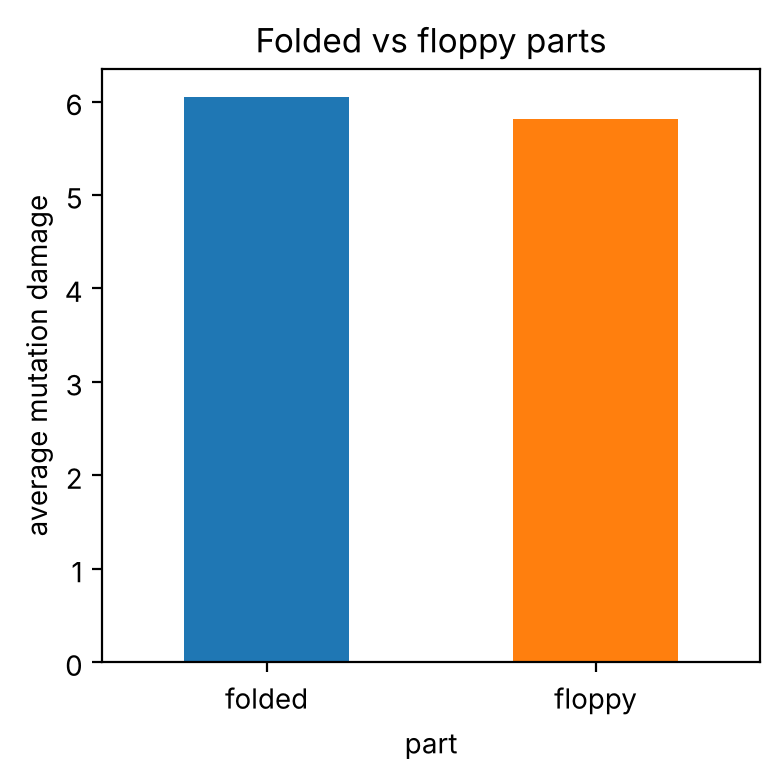

In [6]:
summary[["folded", "floppy"]].plot(kind="bar", color=["tab:blue", "tab:orange"], figsize=(4, 4))
plt.ylabel("average mutation damage")
plt.title("Folded vs floppy parts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/04_folded_vs_floppy.png", dpi=120)
plt.show()

## Same thing, one protein at a time

Some proteins are much longer than others, so I also compare inside each protein that has both parts.

In [7]:
rows = []
for name, group in residues.groupby("protein"):
    folded = group[group["part"] == "folded"]
    floppy = group[group["part"] == "floppy"]
    if len(folded) >= 20 and len(floppy) >= 20:
        rows.append({"protein": name,
                     "folded": folded["damage"].mean(),
                     "floppy": floppy["damage"].mean()})

per_protein = pd.DataFrame(rows).set_index("protein")
per_protein["floppy - folded"] = per_protein["floppy"] - per_protein["folded"]
print((per_protein["floppy - folded"] > 0).sum(), "of", len(per_protein),
      "proteins have better-protected amino acids in their folded part")
per_protein.round(2)

7 of 10 proteins have better-protected amino acids in their folded part


,folded,floppy,floppy - folded
protein,,,
CFTR (cystic fibrosis),5.57,6.23,0.67
DNA ligase 1 (DNA replication),6.18,6.66,0.48
albumin (main blood protein),6.74,4.63,-2.11
alpha-1 antitrypsin (transgenic animals),6.05,6.40,0.35
"collagen (skin, bone)",6.62,5.14,-1.48
factor IX (haemophilia B),6.56,6.57,0.00
factor VIII (haemophilia A),5.88,6.08,0.20
green opsin (colour blindness),5.01,5.33,0.32
p53 (cancer),6.11,6.09,-0.02


## Which proteins make up the floppy group?

The pooled result went the opposite way to the per-protein one, so I checked where the floppy residues come from.

In [8]:
residues[residues["part"] == "floppy"]["protein"].value_counts()

protein
factor VIII (haemophilia A)                 1082
collagen (skin, bone)                        986
DNA ligase 1 (DNA replication)               269
CFTR (cystic fibrosis)                       253
p53 (cancer)                                 117
insulin (recombinant insulin)                 56
green opsin (colour blindness)                55
factor IX (haemophilia B)                     53
red opsin (colour blindness)                  53
alpha-1 antitrypsin (transgenic animals)      43
albumin (main blood protein)                  25
phenylalanine hydroxylase (PKU)               19
rhodopsin (vision in dim light)               17
trypsin (digestion)                           12
DNA polymerase beta (DNA replication)          8
adenosine deaminase (ADA, gene therapy)        7
actin (muscle and cell skeleton)               2
lysozyme (in tears, kills bacteria)            2
calmodulin (calcium signalling)                2
Name: count, dtype: int64

## Without collagen

In [9]:
no_collagen = residues[residues["protein"] != "collagen (skin, bone)"]
no_collagen.groupby("part")["damage"].mean()

part
floppy    6.127654
folded    6.024883
unsure    5.964178
Name: damage, dtype: float64

## Notes

- Pooled over all residues, folded parts were slightly *worse* protected (6.05 vs 5.81 floppy).
- Two proteins make up two-thirds of the floppy residues: factor VIII (1,082) and collagen (986).
  - Factor VIII's middle "B domain" really is disordered, so that's a fair label.
  - Collagen is not really floppy. It's a triple helix (3 chains twisted together), but AlphaFold predicted one chain alone, so its confidence is low. Its G-P-X repeats also have low damage scores.
- Without collagen, folded parts come out slightly better protected (6.02 vs 6.13), the direction I expected.
- Within proteins, 7 of 10 had better-protected amino acids in their folded part, but the differences are small, and 7 of 10 could easily be chance (like getting 7 heads in 10 coin flips).
- Signal peptides (short tags at the start of secreted proteins, e.g. albumin's 25 floppy residues) have low pLDDT but aren't really disordered, so they also blur the result.
- Conclusion: no clear result yet. Low pLDDT doesn't always mean "floppy".
- Next: remove collagen and signal peptides, use more proteins, and add a statistics test.